In [2]:
from google.colab import files
uploaded = files.upload()

Saving internship Dataset to internship Dataset


In [3]:
import pandas as pd

df = pd.read_csv('internship Dataset')
print(df.shape)
print(df['NTU'].value_counts())
df.head()

(399, 6)
NTU
2-3NTU    80
4-5NTU    80
3-4NTU    80
5-6NTU    80
1-2NTU    79
Name: count, dtype: int64


,S No,binary bit R,Binary bit S,Analog value,Analog Voltage,NTU
0,1,1,1,125,0.610352,1-2NTU
1,2,0,0,101,0.493164,1-2NTU
2,3,1,1,123,0.600586,1-2NTU
3,4,0,0,101,0.493164,1-2NTU
4,5,0,0,95,0.463867,1-2NTU


In [4]:
from google.colab import files
uploaded = files.upload()
print(list(uploaded.keys()))

Saving internship Dataset to internship Dataset (1)
['internship Dataset (1)']


In [5]:
import pandas as pd

df = pd.read_csv('internship Dataset')
print(df.shape)
print(df.columns.tolist())
print(df['NTU'].value_counts())
df.head()

(399, 6)
['S No', 'binary bit R', 'Binary bit S', 'Analog value', 'Analog Voltage', 'NTU']
NTU
2-3NTU    80
4-5NTU    80
3-4NTU    80
5-6NTU    80
1-2NTU    79
Name: count, dtype: int64


,S No,binary bit R,Binary bit S,Analog value,Analog Voltage,NTU
0,1,1,1,125,0.610352,1-2NTU
1,2,0,0,101,0.493164,1-2NTU
2,3,1,1,123,0.600586,1-2NTU
3,4,0,0,101,0.493164,1-2NTU
4,5,0,0,95,0.463867,1-2NTU


In [6]:
print(df.isnull().sum())
print("Duplicate rows:", df.duplicated().sum())
print(df['Binary bit S'].value_counts())
print(df.groupby('NTU')['Binary bit S'].value_counts())
print("Mismatch between binary bit R and Binary bit S:")
print((df['binary bit R'] != df['Binary bit S']).sum(), "out of", len(df))

S No              0
binary bit R      0
Binary bit S      0
Analog value      0
Analog Voltage    0
NTU               0
dtype: int64
Duplicate rows: 0
Binary bit S
0    242
1    157
Name: count, dtype: int64
NTU     Binary bit S
1-2NTU  0               47
        1               32
2-3NTU  0               51
        1               29
3-4NTU  0               51
        1               29
4-5NTU  0               47
        1               33
5-6NTU  0               46
        1               34
Name: count, dtype: int64
Mismatch between binary bit R and Binary bit S:
84 out of 399


In [7]:
df['mismatch'] = (df['binary bit R'] != df['Binary bit S']).astype(int)
mismatch_by_ntu = df.groupby('NTU')['mismatch'].agg(['sum', 'count'])
mismatch_by_ntu['error_rate_percent'] = (mismatch_by_ntu['sum'] / mismatch_by_ntu['count'] * 100).round(2)
print(mismatch_by_ntu)

        sum  count  error_rate_percent
NTU                                   
1-2NTU    0     79                0.00
2-3NTU    5     80                6.25
3-4NTU    5     80                6.25
4-5NTU   40     80               50.00
5-6NTU   34     80               42.50


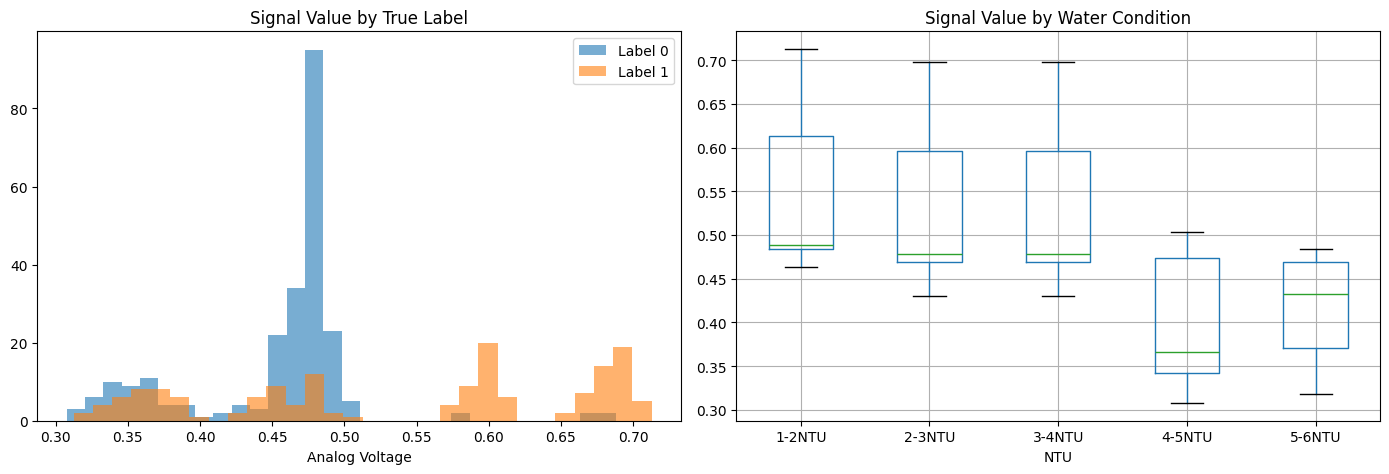

In [8]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14,5))

# Plot 1: feature by true label
axes[0].hist(df[df['Binary bit S']==0]['Analog Voltage'], bins=30, alpha=0.6, label='Label 0')
axes[0].hist(df[df['Binary bit S']==1]['Analog Voltage'], bins=30, alpha=0.6, label='Label 1')
axes[0].set_title('Signal Value by True Label')
axes[0].set_xlabel('Analog Voltage')
axes[0].legend()

# Plot 2: feature by NTU condition
ntu_order = ['1-2NTU', '2-3NTU', '3-4NTU', '4-5NTU', '5-6NTU']
df.boxplot(column='Analog Voltage', by='NTU', ax=axes[1])
axes[1].set_title('Signal Value by Water Condition')
plt.suptitle('')

plt.tight_layout()
plt.show()

In [9]:
from sklearn.model_selection import train_test_split

# Turn NTU into a number the model can use (1, 2, 3, 4, 5 representing increasing turbidity)
ntu_map = {'1-2NTU': 1, '2-3NTU': 2, '3-4NTU': 3, '4-5NTU': 4, '5-6NTU': 5}
df['NTU_level'] = df['NTU'].map(ntu_map)

X = df[['Analog Voltage', 'NTU_level']]
y = df['Binary bit S']

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=42
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, stratify=y_temp, random_state=42
)

print("Train:", X_train.shape, "Val:", X_val.shape, "Test:", X_test.shape)
print("Train class balance:\n", y_train.value_counts(normalize=True))
print("Test class balance:\n", y_test.value_counts(normalize=True))

Train: (279, 2) Val: (60, 2) Test: (60, 2)
Train class balance:
 Binary bit S
0    0.605735
1    0.394265
Name: proportion, dtype: float64
Test class balance:
 Binary bit S
0    0.616667
1    0.383333
Name: proportion, dtype: float64


In [10]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

# Engineered feature: how far each signal value is from its own NTU group's average
df['ntu_mean'] = df.groupby('NTU')['Analog Voltage'].transform('mean')
df['signal_vs_ntu_avg'] = df['Analog Voltage'] - df['ntu_mean']

X_raw = df.loc[X_train.index.union(X_val.index).union(X_test.index), ['Analog Voltage', 'NTU_level']]
X_eng = df.loc[X_raw.index, ['signal_vs_ntu_avg', 'NTU_level']]

# Quick comparison using the same train/test split
from sklearn.model_selection import train_test_split
X_eng_train, X_eng_temp, y_eng_train, y_eng_temp = train_test_split(X_eng, y, test_size=0.3, stratify=y, random_state=42)
X_eng_val, X_eng_test, y_eng_val, y_eng_test = train_test_split(X_eng_temp, y_eng_temp, test_size=0.5, stratify=y_eng_temp, random_state=42)

model_raw = LogisticRegression().fit(X_train, y_train)
model_eng = LogisticRegression().fit(X_eng_train, y_eng_train)

print("Raw features - Test Accuracy:", accuracy_score(y_test, model_raw.predict(X_test)))
print("Engineered features - Test Accuracy:", accuracy_score(y_eng_test, model_eng.predict(X_eng_test)))

Raw features - Test Accuracy: 0.7666666666666667
Engineered features - Test Accuracy: 0.7


In [11]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

# Fixed threshold baseline (using 0.44 like before, applied only to signal value)
y_test_thresh_pred = (X_test['Analog Voltage'] > 0.44).astype(int)

print("=== Fixed Threshold Baseline (Test Set) ===")
print("Accuracy:", accuracy_score(y_test, y_test_thresh_pred))
print("Precision:", precision_score(y_test, y_test_thresh_pred))
print("Recall:", recall_score(y_test, y_test_thresh_pred))
print("F1:", f1_score(y_test, y_test_thresh_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_test_thresh_pred))

# Logistic Regression baseline (using signal value + NTU level)
model_lr = LogisticRegression()
model_lr.fit(X_train, y_train)
y_test_lr_pred = model_lr.predict(X_test)

print("\n=== Logistic Regression Baseline (Test Set) ===")
print("Accuracy:", accuracy_score(y_test, y_test_lr_pred))
print("Precision:", precision_score(y_test, y_test_lr_pred))
print("Recall:", recall_score(y_test, y_test_lr_pred))
print("F1:", f1_score(y_test, y_test_lr_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_test_lr_pred))

=== Fixed Threshold Baseline (Test Set) ===
Accuracy: 0.5166666666666667
Precision: 0.42857142857142855
Recall: 0.782608695652174
F1: 0.5538461538461539
Confusion Matrix:
 [[13 24]
 [ 5 18]]

=== Logistic Regression Baseline (Test Set) ===
Accuracy: 0.7666666666666667
Precision: 0.9090909090909091
Recall: 0.43478260869565216
F1: 0.5882352941176471
Confusion Matrix:
 [[36  1]
 [13 10]]


In [12]:
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

model_svm = SVC(random_state=42)
model_svm.fit(X_train, y_train)
y_test_svm_pred = model_svm.predict(X_test)

print("=== SVM (Test Set) ===")
print("Accuracy:", accuracy_score(y_test, y_test_svm_pred))
print("Precision:", precision_score(y_test, y_test_svm_pred))
print("Recall:", recall_score(y_test, y_test_svm_pred))
print("F1:", f1_score(y_test, y_test_svm_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_test_svm_pred))

model_rf = RandomForestClassifier(random_state=42)
model_rf.fit(X_train, y_train)
y_test_rf_pred = model_rf.predict(X_test)

print("\n=== Random Forest (Test Set) ===")
print("Accuracy:", accuracy_score(y_test, y_test_rf_pred))
print("Precision:", precision_score(y_test, y_test_rf_pred))
print("Recall:", recall_score(y_test, y_test_rf_pred))
print("F1:", f1_score(y_test, y_test_rf_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_test_rf_pred))


=== SVM (Test Set) ===
Accuracy: 0.6166666666666667
Precision: 0.0
Recall: 0.0
F1: 0.0
Confusion Matrix:
 [[37  0]
 [23  0]]


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



=== Random Forest (Test Set) ===
Accuracy: 0.75
Precision: 0.6538461538461539
Recall: 0.7391304347826086
F1: 0.6938775510204082
Confusion Matrix:
 [[28  9]
 [ 6 17]]


In [13]:
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

model_svm = SVC(random_state=42)
model_svm.fit(X_train, y_train)
y_test_svm_pred = model_svm.predict(X_test)

print("=== SVM (Test Set) ===")
print("Accuracy:", accuracy_score(y_test, y_test_svm_pred))
print("Precision:", precision_score(y_test, y_test_svm_pred))
print("Recall:", recall_score(y_test, y_test_svm_pred))
print("F1:", f1_score(y_test, y_test_svm_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_test_svm_pred))

model_rf = RandomForestClassifier(random_state=42)
model_rf.fit(X_train, y_train)
y_test_rf_pred = model_rf.predict(X_test)

print("\n=== Random Forest (Test Set) ===")
print("Accuracy:", accuracy_score(y_test, y_test_rf_pred))
print("Precision:", precision_score(y_test, y_test_rf_pred))
print("Recall:", recall_score(y_test, y_test_rf_pred))
print("F1:", f1_score(y_test, y_test_rf_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_test_rf_pred))

=== SVM (Test Set) ===
Accuracy: 0.6166666666666667
Precision: 0.0
Recall: 0.0
F1: 0.0
Confusion Matrix:
 [[37  0]
 [23  0]]


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



=== Random Forest (Test Set) ===
Accuracy: 0.75
Precision: 0.6538461538461539
Recall: 0.7391304347826086
F1: 0.6938775510204082
Confusion Matrix:
 [[28  9]
 [ 6 17]]


In [14]:
from sklearn.neural_network import MLPClassifier

model_mlp = MLPClassifier(hidden_layer_sizes=(8,), max_iter=1000, random_state=42)
model_mlp.fit(X_train, y_train)
y_test_mlp_pred = model_mlp.predict(X_test)

print("=== Small MLP (Test Set) ===")
print("Accuracy:", accuracy_score(y_test, y_test_mlp_pred))
print("Precision:", precision_score(y_test, y_test_mlp_pred, zero_division=0))
print("Recall:", recall_score(y_test, y_test_mlp_pred, zero_division=0))
print("F1:", f1_score(y_test, y_test_mlp_pred, zero_division=0))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_test_mlp_pred))
print("\nFinal training loss:", model_mlp.loss_)
print("Number of iterations run:", model_mlp.n_iter_)

=== Small MLP (Test Set) ===
Accuracy: 0.6166666666666667
Precision: 0.0
Recall: 0.0
F1: 0.0
Confusion Matrix:
 [[37  0]
 [23  0]]

Final training loss: 0.6656734278502243
Number of iterations run: 66


In [15]:
import time

models = {
    "Fixed Threshold": None,
    "Logistic Regression": model_lr,
    "SVM": model_svm,
    "Random Forest": model_rf,
    "MLP": model_mlp
}

results = []
for name, model in models.items():
    start = time.time()
    if name == "Fixed Threshold":
        preds = (X_test['Analog Voltage'] > 0.44).astype(int)
    else:
        preds = model.predict(X_test)
    elapsed = time.time() - start

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, preds),
        "Precision": precision_score(y_test, preds, zero_division=0),
        "Recall": recall_score(y_test, preds, zero_division=0),
        "F1": f1_score(y_test, preds, zero_division=0),
        "Inference Time (s)": elapsed
    })

comparison_df = pd.DataFrame(results)
print(comparison_df)

                 Model  Accuracy  Precision    Recall        F1  \
0      Fixed Threshold  0.516667   0.428571  0.782609  0.553846   
1  Logistic Regression  0.766667   0.909091  0.434783  0.588235   
2                  SVM  0.616667   0.000000  0.000000  0.000000   
3        Random Forest  0.750000   0.653846  0.739130  0.693878   
4                  MLP  0.616667   0.000000  0.000000  0.000000   

   Inference Time (s)  
0            0.000523  
1            0.001423  
2            0.003381  
3            0.009005  
4            0.001528  


In [16]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV

# Scale features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

# Re-test SVM and MLP on scaled data
model_svm_scaled = SVC(random_state=42)
model_svm_scaled.fit(X_train_scaled, y_train)
preds_svm_scaled = model_svm_scaled.predict(X_test_scaled)
print("SVM (scaled) Accuracy:", accuracy_score(y_test, preds_svm_scaled))
print("SVM (scaled) Precision:", precision_score(y_test, preds_svm_scaled, zero_division=0))
print("SVM (scaled) Recall:", recall_score(y_test, preds_svm_scaled, zero_division=0))
print("SVM (scaled) F1:", f1_score(y_test, preds_svm_scaled, zero_division=0))

model_mlp_scaled = MLPClassifier(hidden_layer_sizes=(8,), max_iter=1000, random_state=42)
model_mlp_scaled.fit(X_train_scaled, y_train)
preds_mlp_scaled = model_mlp_scaled.predict(X_test_scaled)
print("MLP (scaled) Accuracy:", accuracy_score(y_test, preds_mlp_scaled))
print("MLP (scaled) Precision:", precision_score(y_test, preds_mlp_scaled, zero_division=0))
print("MLP (scaled) Recall:", recall_score(y_test, preds_mlp_scaled, zero_division=0))
print("MLP (scaled) F1:", f1_score(y_test, preds_mlp_scaled, zero_division=0))

# GridSearchCV for Random Forest
param_grid_rf = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 5, 10],
    'min_samples_split': [2, 5]
}
grid_rf = GridSearchCV(RandomForestClassifier(random_state=42), param_grid_rf, cv=5, scoring='f1')
grid_rf.fit(X_train, y_train)
print("Best RF params:", grid_rf.best_params_)
best_rf = grid_rf.best_estimator_
preds_rf_tuned = best_rf.predict(X_test)
print("Tuned RF Accuracy:", accuracy_score(y_test, preds_rf_tuned))
print("Tuned RF Precision:", precision_score(y_test, preds_rf_tuned, zero_division=0))
print("Tuned RF Recall:", recall_score(y_test, preds_rf_tuned, zero_division=0))
print("Tuned RF F1:", f1_score(y_test, preds_rf_tuned, zero_division=0))

# GridSearchCV for Logistic Regression
param_grid_lr = {
    'C': [0.01, 0.1, 1, 10],
    'solver': ['liblinear', 'lbfgs']
}
grid_lr = GridSearchCV(LogisticRegression(), param_grid_lr, cv=5, scoring='f1')
grid_lr.fit(X_train, y_train)
print("Best LR params:", grid_lr.best_params_)
best_lr = grid_lr.best_estimator_
preds_lr_tuned = best_lr.predict(X_test)
print("Tuned LR Accuracy:", accuracy_score(y_test, preds_lr_tuned))
print("Tuned LR Precision:", precision_score(y_test, preds_lr_tuned, zero_division=0))
print("Tuned LR Recall:", recall_score(y_test, preds_lr_tuned, zero_division=0))
print("Tuned LR F1:", f1_score(y_test, preds_lr_tuned, zero_division=0))

SVM (scaled) Accuracy: 0.8333333333333334
SVM (scaled) Precision: 0.9333333333333333
SVM (scaled) Recall: 0.6086956521739131
SVM (scaled) F1: 0.7368421052631579
MLP (scaled) Accuracy: 0.8
MLP (scaled) Precision: 0.7894736842105263
MLP (scaled) Recall: 0.6521739130434783
MLP (scaled) F1: 0.7142857142857143
Best RF params: {'max_depth': 5, 'min_samples_split': 5, 'n_estimators': 200}
Tuned RF Accuracy: 0.75
Tuned RF Precision: 0.6666666666666666
Tuned RF Recall: 0.6956521739130435
Tuned RF F1: 0.6808510638297872
Best LR params: {'C': 10, 'solver': 'liblinear'}
Tuned LR Accuracy: 0.75
Tuned LR Precision: 0.7222222222222222
Tuned LR Recall: 0.5652173913043478
Tuned LR F1: 0.6341463414634146


In [17]:
# Build a scaled version of the full test set with NTU labels attached
X_test_with_ntu = X_test.copy()
X_test_with_ntu['NTU'] = df.loc[X_test.index, 'NTU']
X_test_with_ntu['true_label'] = y_test
X_test_with_ntu['threshold_pred'] = (X_test['Analog Voltage'] > 0.44).astype(int)
X_test_with_ntu['svm_scaled_pred'] = model_svm_scaled.predict(scaler.transform(X_test))

print(X_test_with_ntu.groupby('NTU').apply(
    lambda g: pd.Series({
        'rows': len(g),
        'threshold_accuracy': accuracy_score(g['true_label'], g['threshold_pred']),
        'svm_scaled_accuracy': accuracy_score(g['true_label'], g['svm_scaled_pred'])
    })
))

        rows  threshold_accuracy  svm_scaled_accuracy
NTU                                                  
1-2NTU  10.0            0.500000             1.000000
2-3NTU  14.0            0.285714             1.000000
3-4NTU   9.0            0.555556             0.888889
4-5NTU  14.0            0.714286             0.714286
5-6NTU  13.0            0.538462             0.615385


/tmp/ipykernel_4286/2852640559.py:8: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  print(X_test_with_ntu.groupby('NTU').apply(


In [18]:
import joblib
import os

os.makedirs('final_model', exist_ok=True)
os.makedirs('processed_data', exist_ok=True)

# Save the final model AND the scaler (SVM needs the scaler to make predictions later)
joblib.dump(model_svm_scaled, 'final_model/svm_final.pkl')
joblib.dump(scaler, 'final_model/scaler_final.pkl')

# Save the frozen data splits
X_train.to_csv('processed_data/X_train.csv', index=False)
X_val.to_csv('processed_data/X_val.csv', index=False)
X_test.to_csv('processed_data/X_test.csv', index=False)
y_train.to_csv('processed_data/y_train.csv', index=False)
y_val.to_csv('processed_data/y_val.csv', index=False)
y_test.to_csv('processed_data/y_test.csv', index=False)

print("Model kernel:", model_svm_scaled.kernel)
print("Number of support vectors:", model_svm_scaled.n_support_)
print("Model saved. Files in final_model/:", os.listdir('final_model'))
print("Files in processed_data/:", os.listdir('processed_data'))

Model kernel: rbf
Number of support vectors: [59 56]
Model saved. Files in final_model/: ['svm_final.pkl', 'scaler_final.pkl']
Files in processed_data/: ['X_test.csv', 'y_val.csv', 'X_train.csv', 'y_train.csv', 'y_test.csv', 'X_val.csv']


In [19]:
import os
import time

# Reload the frozen model and scaler, just like a fresh deployment would
loaded_model = joblib.load('final_model/svm_final.pkl')
loaded_scaler = joblib.load('final_model/scaler_final.pkl')

X_test_scaled_final = loaded_scaler.transform(X_test)

start = time.time()
final_preds = loaded_model.predict(X_test_scaled_final)
elapsed = time.time() - start

print("Final Test Accuracy:", accuracy_score(y_test, final_preds))
print("Final Test Precision:", precision_score(y_test, final_preds, zero_division=0))
print("Final Test Recall:", recall_score(y_test, final_preds, zero_division=0))
print("Final Test F1:", f1_score(y_test, final_preds, zero_division=0))
print("Total inference time for", len(X_test), "samples:", elapsed, "seconds")
print("Per-sample time:", elapsed/len(X_test), "seconds")

model_size = os.path.getsize('final_model/svm_final.pkl')
scaler_size = os.path.getsize('final_model/scaler_final.pkl')
print("Model file size:", model_size, "bytes")
print("Scaler file size:", scaler_size, "bytes")

Final Test Accuracy: 0.8333333333333334
Final Test Precision: 0.9333333333333333
Final Test Recall: 0.6086956521739131
Final Test F1: 0.7368421052631579
Total inference time for 60 samples: 0.0013954639434814453 seconds
Per-sample time: 2.325773239135742e-05 seconds
Model file size: 5771 bytes
Scaler file size: 935 bytes


In [20]:
from sklearn.metrics import confusion_matrix

final_preds = loaded_model.predict(loaded_scaler.transform(X_test))

cm = confusion_matrix(y_test, final_preds)
print("Confusion Matrix:")
print(cm)

# Build a table of the actual misclassified rows
error_df = X_test.copy()
error_df['NTU'] = df.loc[X_test.index, 'NTU']
error_df['true_label'] = y_test
error_df['predicted_label'] = final_preds
error_df['correct'] = error_df['true_label'] == error_df['predicted_label']

misclassified = error_df[error_df['correct'] == False]
print("\nNumber of misclassified rows:", len(misclassified))
print("\nMisclassified rows:")
print(misclassified[['Analog Voltage', 'NTU', 'true_label', 'predicted_label']])

print("\nMisclassified rows by NTU condition:")
print(misclassified['NTU'].value_counts())

print("\nError type breakdown:")
print("False Positives (predicted 1, actually 0):", len(misclassified[(misclassified['true_label']==0) & (misclassified['predicted_label']==1)]))
print("False Negatives (predicted 0, actually 1):", len(misclassified[(misclassified['true_label']==1) & (misclassified['predicted_label']==0)]))

Confusion Matrix:
[[36  1]
 [ 9 14]]

Number of misclassified rows: 10

Misclassified rows:
     Analog Voltage     NTU  true_label  predicted_label
268        0.473633  4-5NTU           1                0
350        0.380859  5-6NTU           1                0
327        0.478516  5-6NTU           1                0
164        0.688477  3-4NTU           0                1
290        0.473633  4-5NTU           1                0
284        0.336914  4-5NTU           1                0
360        0.454102  5-6NTU           1                0
363        0.361328  5-6NTU           1                0
288        0.341797  4-5NTU           1                0
356        0.390625  5-6NTU           1                0

Misclassified rows by NTU condition:
NTU
5-6NTU    5
4-5NTU    4
3-4NTU    1
Name: count, dtype: int64

Error type breakdown:
False Positives (predicted 1, actually 0): 1
False Negatives (predicted 0, actually 1): 9
